# Playbook · Cover a company

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/valuein/valuein/blob/main/examples/playbooks/cover-a-company.ipynb)

**Who it is for:** equity analysts and investors who are starting coverage of one company.

**What you get:** three statements, ratios, restatement history and a sourced export, each number with its filing, then the clicks that do the same in the Workspace.

**Plan needed:** none for the code (free sample, no key). The Workspace section works on the free Benchmark account.

## Step 1 · Find the company

Resolve a ticker to its CIK once. Tickers are reused over time; the CIK is the company's permanent key.

In [1]:
%pip install -q "valuein-sdk>=1.1.0" matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

from valuein_sdk import ValueinClient

warnings.filterwarnings("ignore", message="Defaulting to SAMPLE dataset")
client = ValueinClient()
TICKER = "MSFT"
company = client.resolve(TICKER).iloc[0]
print(company[["name", "cik", "symbol", "is_active"]].to_string())

Using the free sample means accepting the Valuein Data Licence: valuein.biz/terms#data-licence


name         MICROSOFT CORP
cik              0000789019
symbol                 MSFT
is_active              True


### Pull the three statements

`financials` returns income, balance sheet and cash flow as known today, one column per fiscal year, in USD.

In [3]:
fin = client.financials(TICKER, periods=5)
KEY = {"income": ["TotalRevenue", "GrossProfit", "OperatingIncome", "NetIncome"],
       "balance": ["TotalAssets", "TotalLiabilities", "StockholdersEquity"],
       "cash_flow": ["OperatingCashFlow", "CAPEX"]}
summary = pd.concat({name: getattr(fin, name).reindex(rows) for name, rows in KEY.items()})
(summary / 1e9).round(2)

period_end                    2022-06-30  2023-06-30  2024-06-30  2025-06-30  \
          concept                                                              
income    TotalRevenue            198.27      211.92      245.12      281.72   
          GrossProfit             135.62      146.05      171.01      193.89   
          OperatingIncome          83.38       88.52      109.43      128.53   
          NetIncome                72.74       72.36       88.14      101.83   
balance   TotalAssets             364.84      411.98      512.16      619.00   
          TotalLiabilities        198.30      205.75      243.69      275.52   
          StockholdersEquity         NaN         NaN         NaN         NaN   
cash_flow OperatingCashFlow        89.04       87.58      118.55      136.16   
          CAPEX                    23.89       28.11       44.48       64.55   

period_end                    2026-06-30  
          concept                         
income    TotalRevenue            331.84  
          GrossProfit             225.46  
          OperatingIncome         155.24  
          NetIncome               133.75  
balance   TotalAssets             758.38  
          TotalLiabilities        315.99  
          StockholdersEquity         NaN  
cash_flow OperatingCashFlow       182.94  
          CAPEX                   115.95

**Check it worked:** the company name, its 10-digit CIK and `is_active: True`.

Then: a table of key lines (USD billions) with five fiscal years as columns.

## Step 2 · See the numbers

A quick look at the two lines every note starts with.

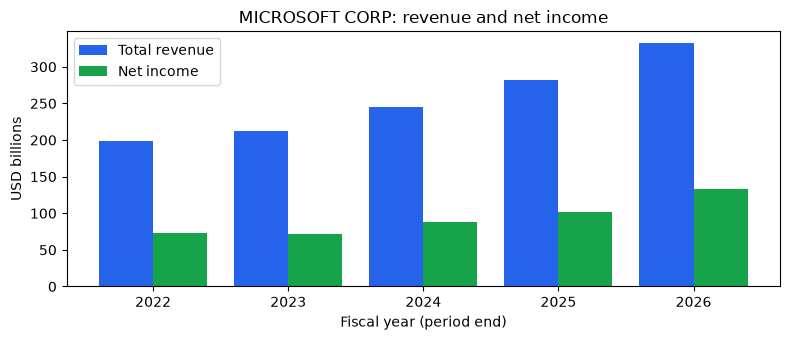

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.5))
years = [d.year for d in fin.income.columns]
ax.bar([y - 0.2 for y in years], fin.income.loc["TotalRevenue"] / 1e9, width=0.4, label="Total revenue", color="#2563eb")
ax.bar([y + 0.2 for y in years], fin.income.loc["NetIncome"] / 1e9, width=0.4, label="Net income", color="#16a34a")
ax.set_xlabel("Fiscal year (period end)")
ax.set_ylabel("USD billions")
ax.set_title(f"{company['name']}: revenue and net income")
ax.legend()
plt.tight_layout()
plt.show()

### Every number has a receipt

`fin.lineage` has one row per number: its `fact_id`, the filing (`accession_id`, `form_type`) and when the SEC accepted it.

In [5]:
lineage = fin.lineage
revenue = lineage[(lineage["concept"] == "TotalRevenue")].sort_values("period_end")
revenue[["period_end", "value", "form_type", "accession_id", "accepted_at", "fact_id"]].tail(3).to_string(index=False)

'period_end        value form_type         accession_id               accepted_at                                                          fact_id\n2024-06-30 2.451220e+11      10-K 0001193125-26-323660 2026-07-29 20:08:01+00:00 e297ed6d6f6ccb6ebb98ac0d1bacbbdd3e0e425936f5e5d4b2c6cd5d89358578\n2025-06-30 2.817240e+11      10-K 0001193125-26-323660 2026-07-29 20:08:01+00:00 ca16c298b43280703df2c89303a157d18ffd6da626b83eab15ea043394ae3308\n2026-06-30 3.318390e+11      10-K 0001193125-26-323660 2026-07-29 20:08:01+00:00 a7aea8c253e16ede99fa746897c341aa83b13ade9b76680d5c41946a4fc3f39b'

**Check it worked:** a bar chart with five fiscal years of revenue and net income.

Then: the last three fiscal years of revenue, each with a form type, an accession and a 64-character `fact_id`.

## Step 3 · Verify one figure against its filing

Rebuild the `fact_id` from the filing facts and open the exact document. If the ids match, the number is the one in the filing record.

In [6]:
from valuein_sdk import compute_fact_id

facts = client.read_table("fact", tickers=TICKER)
fy = facts[(facts["standard_concept"] == "TotalRevenue") & (facts["fiscal_period"] == "FY")]
row = fy.sort_values(["period_end", "accepted_at", "priority"]).iloc[-1]
rebuilt = compute_fact_id(row["entity_id"], row["accession_id"], row["concept"],
                          row["period_end"].date(), row["unit"])
print("fact_id from the data:", row["fact_id"])
print("fact_id rebuilt      :", rebuilt)
print("match                :", rebuilt == row["fact_id"])

links = client.filing_links(TICKER, form_types=["10-K"], limit=5)
hit = links[links["accession_id"] == row["accession_id"]]
if not hit.empty:
    print("open the filing      :", hit.iloc[0]["inline_viewer_url"] or hit.iloc[0]["sec_url"])

fact_id from the data: a7aea8c253e16ede99fa746897c341aa83b13ade9b76680d5c41946a4fc3f39b
fact_id rebuilt      : a7aea8c253e16ede99fa746897c341aa83b13ade9b76680d5c41946a4fc3f39b
match                : True
open the filing      : https://www.sec.gov/ix?doc=/Archives/edgar/data/789019/000119312526323660/msft-20260630.htm


### Check whether any number was changed later

Restatement Radar lists numbers a later filing changed. `non_reliance` means an 8-K Item 4.02, `amended` a 10-K/A or 10-Q/A, `undisclosed` a change inside a routine 10-K or 10-Q. The class describes how it was disclosed, nothing more.

In [7]:
events = client.restatements(ticker=TICKER, limit=500)
print(f"{len(events)} changed values for {TICKER}")
if len(events):
    print(events["disclosure_class"].value_counts().to_string())
    cols = ["standard_concept", "period_end", "first_value", "current_value", "disclosure_class"]
    print(events[cols].head(5).to_string(index=False))

10 changed values for MSFT
disclosure_class
undisclosed    10
standard_concept period_end  first_value  current_value disclosure_class
    PretaxIncome 2017-06-30 2.314900e+10   2.990100e+10      undisclosed
 OperatingIncome 2017-06-30 2.232600e+10   2.902500e+10      undisclosed
    ParentEquity 2017-06-30 7.239400e+10   8.771100e+10      undisclosed
 OperatingIncome 2016-12-31 6.177000e+09   7.905000e+09      undisclosed
 OperatingIncome 2016-06-30 2.018200e+10   2.607800e+10      undisclosed


**Check it worked:** `match: True` and a sec.gov link to the filing the number came from.

Then: a count of changed values by disclosure class (possibly zero), each row with its first and current value.

## Step 4 · Export a sourced table

Write the statements with the `fact_id` and filing behind every number, so a reviewer can trace each cell.

In [8]:
sourced = (lineage[["statement", "concept", "period_end", "value", "unit", "form_type",
                    "accession_id", "accepted_at", "fact_id"]]
           .sort_values(["statement", "concept", "period_end"]))
sourced.to_csv(f"{TICKER.lower()}_statements_sourced.csv", index=False)
print(len(sourced), "sourced numbers written to", f"{TICKER.lower()}_statements_sourced.csv")
client.close()

607 sourced numbers written to msft_statements_sourced.csv


**Check it worked:** a CSV with one row per number and its `fact_id` beside it.

## In the Workspace

The Workspace does the same job without code, on the free Benchmark account.

1. Click **Start free** on valuein.biz and sign in. The Workspace opens on Chat.
2. Ask: "Cover Microsoft: three statements for the last five years, the ratios that moved most, and anything a later filing restated. Cite the filing for every figure."
3. Click any figure in the answer to open its receipt: form, period, filed date, accession and fact reference.
4. Save the answer as a report. Open the report's Figures panel to see each figure checked against its filing; a figure the check cannot confirm goes to a person, never shown as a pass.
5. Download the report from the report page.

**Next:** [DDQ: answer the AI question](ddq-ai-question.ipynb) · [Fundamentals as of a date](../notebooks/02_fundamentals_as_of_a_date.ipynb)

_Index names are trademarks of their owners; Valuein is not affiliated with or endorsed by any index provider._